# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib


# Data Loading

In [2]:
df = pd.read_csv('tlast3.csv')
print('Original shape:', df.shape)
print(df.head())
print('\nMissing values:\n', df.isnull().sum())


Original shape: (162567, 11)
         date    source              destination  distance_km  \
0  15-07-2022     Powai                   Airoli    14.256019   
1  14-06-2024  Dombivli                   Mulund    17.796597   
2  02-05-2022       CST                 Goregaon    37.720590   
3  01-09-2024    Airoli  Western Express Highway    26.552190   
4  31-03-2022     Kurla          Crawford Market    17.001971   

   congestion_index time_of_day     weather day_of_week festival  \
0          0.293694       13:12      Cloudy      Friday      NaN   
1          0.436896       09:11      Cloudy      Friday      NaN   
2          0.505821       02:17  Heavy Rain      Monday      Eid   
3          0.344714       22:30        Rain      Sunday      NaN   
4          0.243654       01:50      Cloudy    Thursday      NaN   

   actual_travel_time_min road_type  
0               32.814877     urban  
1               58.923626       NaN  
2              114.466769     urban  
3               51.

# Data Preprocessing & Feature Engineering

In [3]:
# Drop festival column
df.drop(columns=['festival'], inplace=True)

# Fill missing numerical values with median
num_cols = ['distance_km', 'congestion_index', 'actual_travel_time_min']
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
cat_cols = ['weather', 'road_type', 'time_of_day']
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# --- Extract date features ---
# day_of_week and month derived from date — not from CSV column
# day_of_month skipped — too noisy without multiple years of data
df['date']        = pd.to_datetime(df['date'], errors='coerce')
df['day_of_week'] = df['date'].dt.day_name()  # overwrite CSV column
df['month']       = df['date'].dt.month       # 1=Jan ... 10=Oct(Dashain)

# --- Parse time ---
time_parsed         = pd.to_datetime(df['time_of_day'], format='%H:%M', errors='coerce')
df['time_in_hours'] = time_parsed.dt.hour + time_parsed.dt.minute / 60

# --- One-hot encode ---
# Baselines dropped: road_type=congested, day_of_week=Friday, weather=Clear
df = pd.get_dummies(
    df,
    columns=['road_type', 'day_of_week', 'weather'],
    drop_first=True,
    dtype=int
)

df.dropna(inplace=True)

print('Columns after encoding:')
print(df.columns.tolist())
print('Shape:', df.shape)


C:\Users\Ronish\AppData\Local\Temp\ipykernel_11596\1160934338.py:17: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['date']        = pd.to_datetime(df['date'], errors='coerce')


Columns after encoding:
['date', 'source', 'destination', 'distance_km', 'congestion_index', 'time_of_day', 'actual_travel_time_min', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']
Shape: (162285, 22)


# Outlier Removal

In [4]:
numerical_cols = ['distance_km', 'congestion_index', 'time_in_hours', 'actual_travel_time_min']

Q1  = df[numerical_cols].quantile(0.25)
Q3  = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1
df  = df[~((df[numerical_cols] < (Q1 - 1.5 * IQR)) |
           (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)]

print('Shape after outlier removal:', df.shape)


Shape after outlier removal: (156223, 22)


# Congestion Prediction Model

In [ ]:

X = df.drop(columns=[
    'congestion_index',        
    'actual_travel_time_min',  
    'date',                    
    'source',                  
    'destination',            
    'time_of_day',             
])
y = df['congestion_index']

print('Features used for congestion prediction:')
for col in X.columns:
    print(' -', col)


Features used for congestion prediction:
 - distance_km
 - month
 - time_in_hours
 - road_type_freeway
 - road_type_urban
 - day_of_week_Monday
 - day_of_week_Saturday
 - day_of_week_Sunday
 - day_of_week_Thursday
 - day_of_week_Tuesday
 - day_of_week_Wednesday
 - weather_Cloudy
 - weather_Fog
 - weather_Heavy Rain
 - weather_Rain
 - weather_Storm


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training shape:', X_train.shape)
print('Test shape:    ', X_test.shape)


Training shape: (124978, 16)
Test shape:     (31245, 16)


In [7]:
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=5,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)
print('Model trained.')


Model trained.


# Model Evaluation

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=kf, scoring='neg_root_mean_squared_error')
print(f'CV RMSE: {-cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})')
print(f'CV scores: {-cv_scores}')

y_train_pred = model.predict(X_train)
y_test_pred  = model.predict(X_test)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse  = np.sqrt(mean_squared_error(y_test,  y_test_pred))
train_mae  = mean_absolute_error(y_train, y_train_pred)
test_mae   = mean_absolute_error(y_test,  y_test_pred)
train_r2   = r2_score(y_train, y_train_pred)
test_r2    = r2_score(y_test,  y_test_pred)

print('\nCongestion Model Performance:')
print(f'  Train RMSE: {train_rmse:.4f}  |  Test RMSE: {test_rmse:.4f}')
print(f'  Train MAE:  {train_mae:.4f}  |  Test MAE:  {test_mae:.4f}')
print(f'  Train R2:   {train_r2:.4f}  |  Test R2:  {test_r2:.4f}')


CV RMSE: 0.0271 (+/- 0.0002)
CV scores: [0.02686923 0.02716396 0.02719724 0.02690173 0.0273721 ]

Congestion Model Performance:
  Train RMSE: 0.0256  |  Test RMSE: 0.0272
  Train MAE:  0.0191  |  Test MAE:  0.0204
  Train R2:   0.9564  |  Test R2:  0.9503


# Feature Importance

TOP FEATURES FOR CONGESTION PREDICTION:
 1. time_in_hours                            0.3930
 2. road_type_urban                          0.0984
 3. road_type_freeway                        0.0905
 4. weather_Heavy Rain                       0.0860
 5. weather_Rain                             0.0798
 6. weather_Storm                            0.0670
 7. day_of_week_Saturday                     0.0400
 8. distance_km                              0.0398
 9. day_of_week_Wednesday                    0.0240
10. day_of_week_Sunday                       0.0212


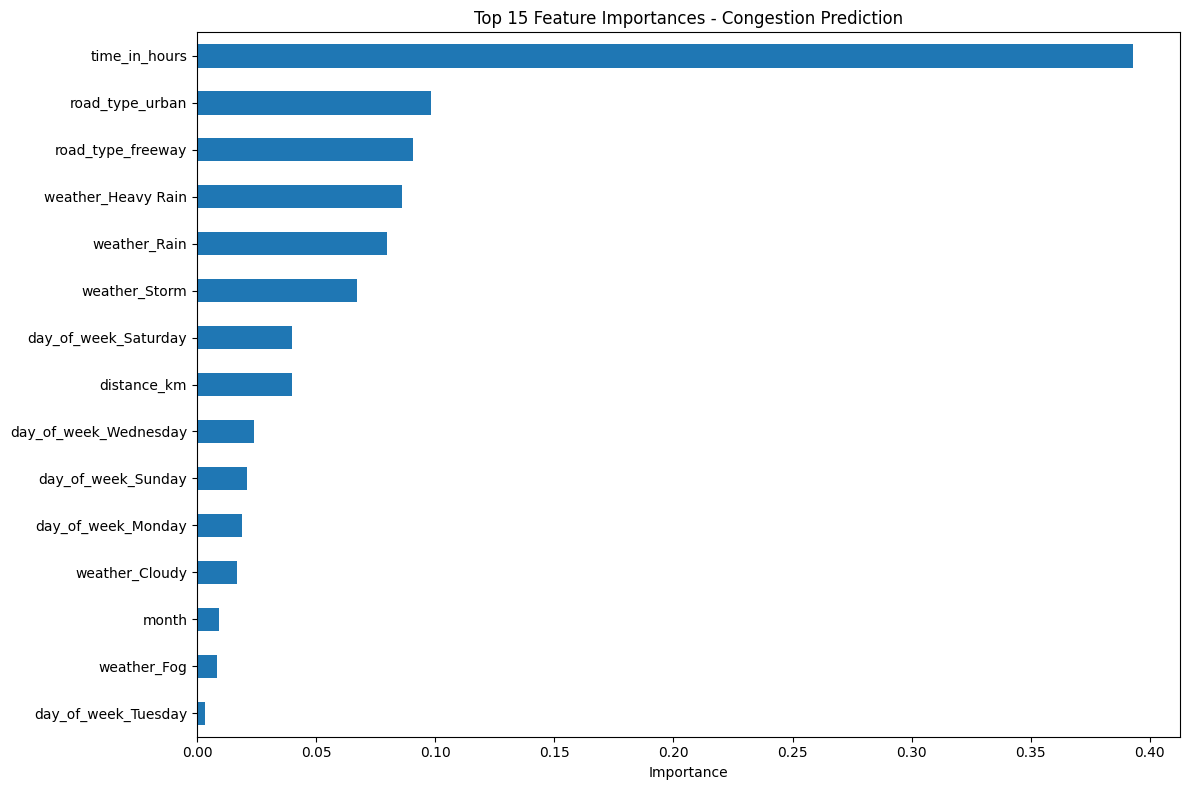

In [9]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print('TOP FEATURES FOR CONGESTION PREDICTION:')
print('='*55)
for i, (feat, imp) in enumerate(feature_importance.head(10).items(), 1):
    print(f'{i:2d}. {feat:40s} {imp:.4f}')

plt.figure(figsize=(12, 8))
feature_importance.head(15).sort_values().plot(kind='barh')
plt.xlabel('Importance')
plt.title('Top 15 Feature Importances - Congestion Prediction')
plt.tight_layout()
plt.savefig('congestion_feature_importance.png', dpi=300)
plt.show()


# Visualizations

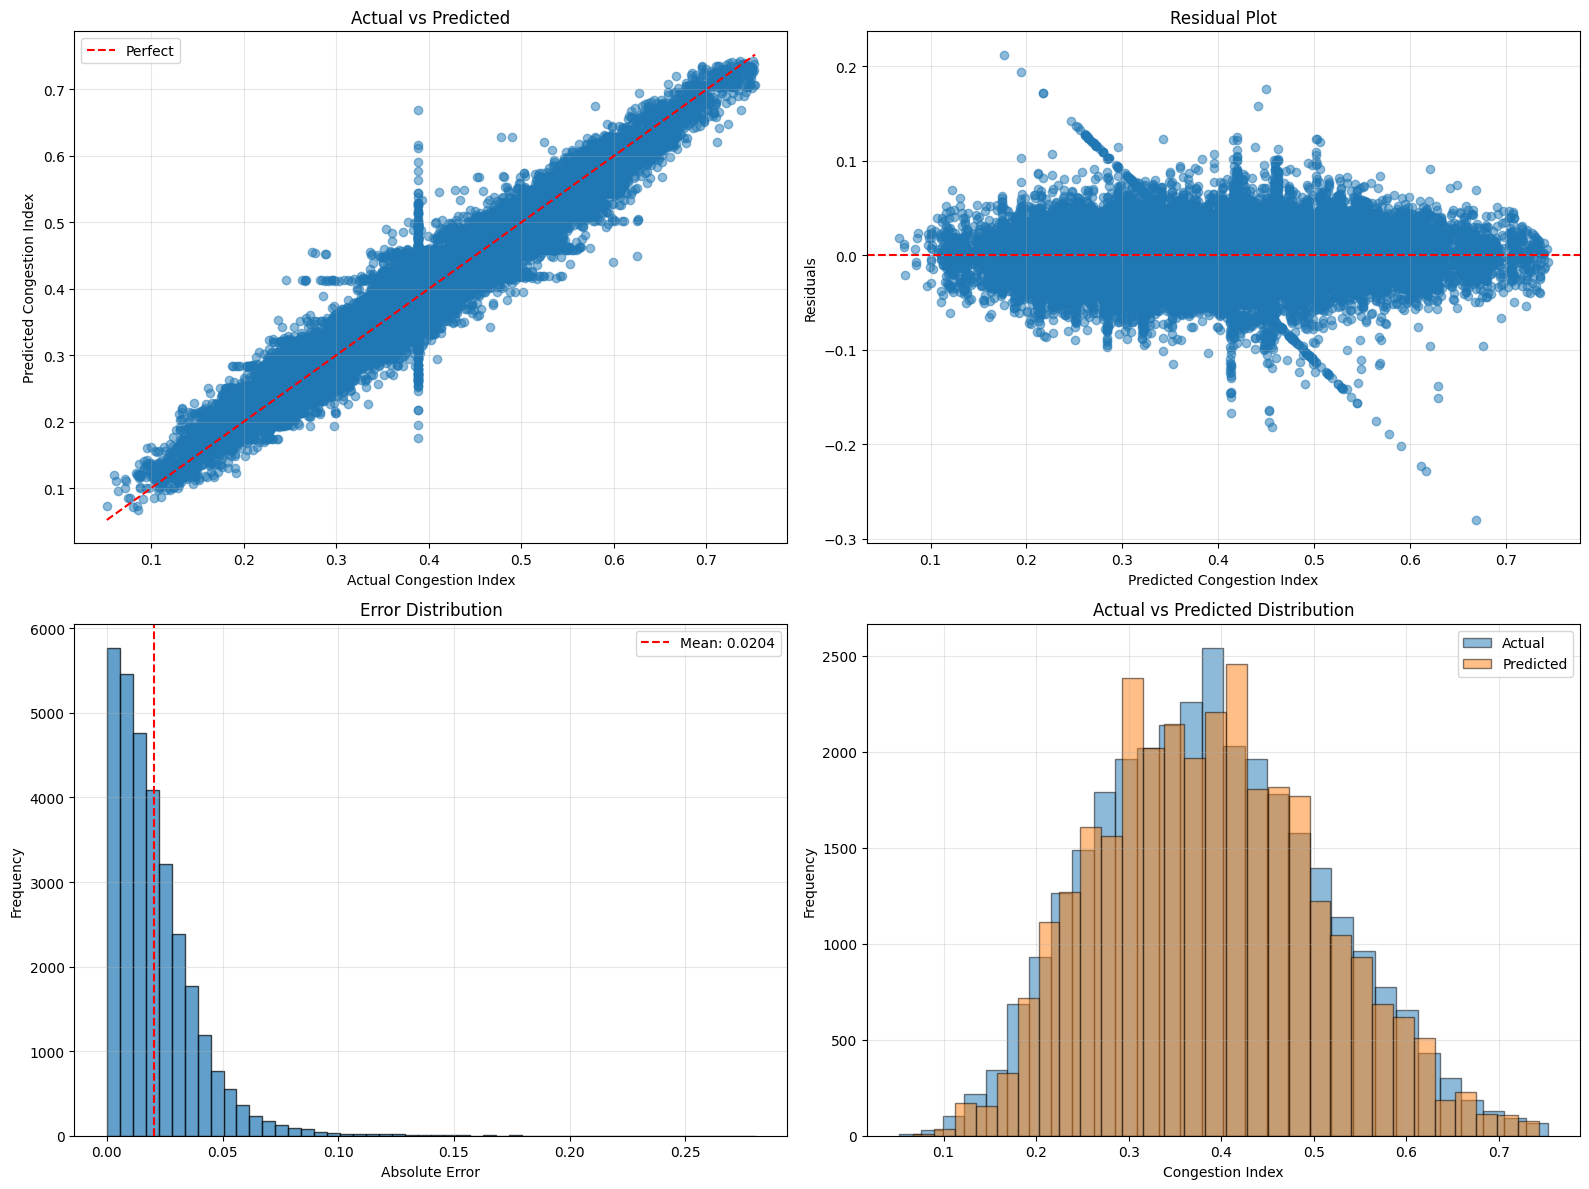

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Actual vs Predicted
axes[0,0].scatter(y_test, y_test_pred, alpha=0.5)
axes[0,0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Perfect')
axes[0,0].set_xlabel('Actual Congestion Index')
axes[0,0].set_ylabel('Predicted Congestion Index')
axes[0,0].set_title('Actual vs Predicted')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Residuals
residuals = y_test - y_test_pred
axes[0,1].scatter(y_test_pred, residuals, alpha=0.5)
axes[0,1].axhline(y=0, color='r', linestyle='--')
axes[0,1].set_xlabel('Predicted Congestion Index')
axes[0,1].set_ylabel('Residuals')
axes[0,1].set_title('Residual Plot')
axes[0,1].grid(True, alpha=0.3)

# Error Distribution
axes[1,0].hist(np.abs(residuals), bins=50, edgecolor='black', alpha=0.7)
axes[1,0].axvline(np.abs(residuals).mean(), color='r', linestyle='--',
                  label=f'Mean: {np.abs(residuals).mean():.4f}')
axes[1,0].set_xlabel('Absolute Error')
axes[1,0].set_ylabel('Frequency')
axes[1,0].set_title('Error Distribution')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# Prediction Distribution
axes[1,1].hist(y_test,      bins=30, alpha=0.5, label='Actual',    edgecolor='black')
axes[1,1].hist(y_test_pred, bins=30, alpha=0.5, label='Predicted', edgecolor='black')
axes[1,1].set_xlabel('Congestion Index')
axes[1,1].set_ylabel('Frequency')
axes[1,1].set_title('Actual vs Predicted Distribution')
axes[1,1].legend()
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('congestion_model_analysis.png', dpi=300, bbox_inches='tight')
plt.show()


# Save Model

In [12]:
joblib.dump(model, 'cv2.pkl')
print('Saved: congestion_prediction_model_v2.pkl')
print('Features the model expects:')
print(model.feature_names_in_.tolist())


Saved: congestion_prediction_model_v2.pkl
Features the model expects:
['distance_km', 'month', 'time_in_hours', 'road_type_freeway', 'road_type_urban', 'day_of_week_Monday', 'day_of_week_Saturday', 'day_of_week_Sunday', 'day_of_week_Thursday', 'day_of_week_Tuesday', 'day_of_week_Wednesday', 'weather_Cloudy', 'weather_Fog', 'weather_Heavy Rain', 'weather_Rain', 'weather_Storm']
